# II. Buscas clássicas

In [ ]:
from collections import deque
import random
import time

import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
import numpy as np

## II.B. Subrotinas para flips

In [ ]:
def flip_um(estado, pos):
    estado[pos] ^= 1
    return 1, bytes(estado)


def flip_n(estado, pos, n):
    for i in range(pos, pos + n):
        estado[i] ^= 1

    return 1, bytes(estado)


seq = bytes(int(bit) for bit in "00001001000011001100111")
result = bytes(len(seq))  # Cria uma sequência de zeros do mesmo tamanho.

custo = 0
nova = bytearray(seq)
c, _ = flip_um(nova, 4)
custo += c
c, _ = flip_um(nova, 7)
custo += c
c, _ = flip_n(nova, 12, 2)
custo += c
c, _ = flip_n(nova, 16, 2)
custo += c
c, _ = flip_n(nova, 20, 3)
custo += c

print(f"I: {list(seq)}")
print(f"F: {list(nova)}")
print(f"R: {list(result)}")
print(f"Bateu? {nova == result}")
print(f"Custo: {custo}")

I: [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1]
F: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
R: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Bateu? True
Custo: 5


## II.C. Busca em largura, BFS

In [ ]:
def bfs(inicio, resultado):

    estados = deque([inicio])
    achou = inicio == resultado
    caminho = {inicio: None}
    custo_um = 1
    custo_n = 1

    while estados and not achou:
        estado = estados.popleft()

        # Gera todos os flips de um bit ou de um intervalo consecutivo.
        for i in range(len(estado)):
            nova = bytearray(estado)  # Uma cópia para cada início de intervalo.

            for j in range(i, len(estado)):

                nova[j] ^= 1
                vizinho = bytes(nova)

                if vizinho not in caminho:

                    if i == j:
                        c = custo_um
                        op = (i, 1)

                    else:
                        quantidade_bits = j - i + 1
                        c = custo_n
                        op = (i, quantidade_bits)

                    caminho[vizinho] = (estado, op, c)

                    if vizinho == resultado:
                        achou = True
                        break

                    estados.append(vizinho)

            if achou:
                break

    if not achou:
        return False, [], None

    ops = []
    custo = 0
    estado = resultado

    while caminho[estado]:
        pai, op, c = caminho[estado]
        ops.append(op)
        custo += c
        estado = pai

    ops.reverse()
    return True, ops, custo


seq = bytes(int(bit) for bit in "00001001000011001100111")
result = bytes(len(seq))

t0 = time.perf_counter()
achou, ops, custo = bfs(seq, result)
t1 = time.perf_counter()

if achou:
    print("Achou")

    # Cada operação retornada é (posição, quantidade de bits).
    nomes_ops = []
    for pos, quantidade in ops:
        if quantidade == 1:
            nomes_ops.append(f"flip_um({pos})")
        else:
            nomes_ops.append(f"flip_n({pos}, {quantidade})")

    print("Operações:", nomes_ops)
    print("Custo", custo)
    print()

    print("Rodando as ops para verificar se bate com o resultado final:")
    nova = bytearray(seq)
    custo_verificado = 0

    print(f"  Inicial: {list(nova)}")
    print()

    for pos, quantidade in ops:
        if quantidade == 1:
            print(f"  flip_um({pos})")
            c, _ = flip_um(nova, pos)
        else:
            print(f"  flip_n({pos}, {quantidade})")
            c, _ = flip_n(nova, pos, quantidade)

        custo_verificado += c
        print(f"  Nova:    {list(nova)}")
        print()

    print(f"  Bateu? {bytes(nova) == result}")
    print(f"  Custo verificado: {custo_verificado}")
else:
    print("Não Achou")

print()
print(f"Tempo de execução da BFS: {t1 - t0:.4f} segundos")

Achou
Operações: ['flip_um(4)', 'flip_um(7)', 'flip_n(12, 2)', 'flip_n(16, 2)', 'flip_n(20, 3)']
Custo 5

Rodando as ops para verificar se bate com o resultado final:
  Inicial: [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1]

  flip_um(4)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1]

  flip_um(7)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1]

  flip_n(12, 2)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1]

  flip_n(16, 2)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1]

  flip_n(20, 3)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

  Bateu? True
  Custo verificado: 5

Tempo de execução da BFS: 38.1621 segundos


## II.D. Algoritmo guloso

In [ ]:
def guloso(inicio, resultado):

    # A heurística conta quantas posições ainda precisam mudar para chegar ao alvo.
    # Em cada passo, segue-se para o vizinho não visitado com menos posições erradas.
    # Ele parece mais fácil de corrigir, pois exige menos mudanças individuais.

    def heuristica(estado, resultado):
        erro = 0

        for pos in range(len(estado)):
            if estado[pos] != resultado[pos]:
                erro += 1

        return erro

    estados = [inicio]
    achou = inicio == resultado
    caminho = {inicio: None}
    custo_um = 1
    custo_n = 1

    while estados and not achou:
        estado = estados.pop()
        erro_atual = heuristica(estado, resultado)
        melhor_vizinho = None
        melhor_erro = float("inf")

        for i in range(len(estado)):
            nova = bytearray(estado)
            erro = erro_atual

            for j in range(i, len(estado)):
                nova[j] ^= 1

                if nova[j] != resultado[j]:
                    erro += 1
                    
                else:
                    erro -= 1

                if erro < melhor_erro:
                    vizinho = bytes(nova)

                    if vizinho not in caminho:
                        melhor_vizinho = vizinho
                        melhor_erro = erro
                        quantidade_bits = j - i + 1
                        melhor_op = (i, quantidade_bits)
                        melhor_custo = custo_um if quantidade_bits == 1 else custo_n

        if melhor_vizinho is None:
            break

        # Guarda somente o vizinho com menor erro
        caminho[melhor_vizinho] = (estado, melhor_op, melhor_custo)

        if melhor_vizinho == resultado:
            achou = True

        if not achou:
            estados.append(melhor_vizinho)

    if not achou:
        return False, [], None

    ops = []
    custo = 0
    estado = resultado

    while caminho[estado]:
        pai, op, c = caminho[estado]
        ops.append(op)
        custo += c
        estado = pai

    ops.reverse()
    return True, ops, custo


seq = bytes(int(bit) for bit in "00001001000011001100111")
result = bytes(len(seq))

t0 = time.perf_counter()
achou, ops, custo = guloso(seq, result)
t1 = time.perf_counter()

if achou:
    print("Achou")

    nomes_ops = []
    for pos, quantidade in ops:
        if quantidade == 1:
            nomes_ops.append(f"flip_um({pos})")
        else:
            nomes_ops.append(f"flip_n({pos}, {quantidade})")

    print("Operações:", nomes_ops)
    print("Custo", custo)
    print()

    print("Rodando as ops para verificar se bate com o resultado final:")
    nova = bytearray(seq)
    custo_verificado = 0

    print(f"  Inicial: {list(nova)}")
    print()

    for pos, quantidade in ops:
        if quantidade == 1:
            print(f"  flip_um({pos})")
            c, _ = flip_um(nova, pos)
        else:
            print(f"  flip_n({pos}, {quantidade})")
            c, _ = flip_n(nova, pos, quantidade)

        custo_verificado += c
        print(f"  Nova:    {list(nova)}")
        print()

    print(f"  Bateu? {bytes(nova) == result}")
    print(f"  Custo verificado: {custo_verificado}")
else:
    print("Não Achou")

print()
print(f"Tempo de execução do Guloso: {t1 - t0:.4f} segundos")

Achou
Operações: ['flip_n(12, 11)', 'flip_n(14, 2)', 'flip_n(18, 2)', 'flip_um(4)', 'flip_um(7)']
Custo 5

Rodando as ops para verificar se bate com o resultado final:
  Inicial: [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1]

  flip_n(12, 11)
  Nova:    [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0]

  flip_n(14, 2)
  Nova:    [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0]

  flip_n(18, 2)
  Nova:    [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

  flip_um(4)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

  flip_um(7)
  Nova:    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

  Bateu? True
  Custo verificado: 5

Tempo de execução do Guloso: 0.0001 segundos


## II.E. Comparação de desempenho

In [ ]:
seed = 42
random.seed(seed)

expoente = 4 # 2^(0 + 1) = 2, 2^(1 + 1) = 4, 2^(2 + 1) = 8, 2^(3 + 1) = 16 (comprimento da sequência)
experimentos = 50 # roda 50 experimentos para cada tamanho de sequência

resultados = []

for i in range(expoente):

    tamanho = 2 ** (i + 1)
    resultados_tamanho = []

    for j in range(experimentos):

        inicio = bytes(random.choices([0, 1], k=tamanho))
        resultado = bytes(random.choices([0, 1], k=tamanho))

        inicio_bfs = time.perf_counter()
        bateu_bfs, ops_bfs, custo_bfs = bfs(inicio, resultado)
        tempo_bfs = time.perf_counter() - inicio_bfs

        inicio_guloso = time.perf_counter()
        bateu_guloso, ops_guloso, custo_guloso = guloso(inicio, resultado)
        tempo_guloso = time.perf_counter() - inicio_guloso

        resultados_tamanho.append((tamanho, tempo_bfs, bateu_bfs, custo_bfs, tempo_guloso, bateu_guloso, custo_guloso, len(ops_bfs), len(ops_guloso)))

        if j % 10 == 0:
            print(f"Tamanho: {tamanho}, Experimento: {j + 1}/{experimentos}")

    print()

    resultados.append(resultados_tamanho)

print()
print("Resultado médio dos experimentos por tamanho:")
print()
for resultados_tamanho in resultados:

    total_tempo_bfs = sum(r[1] for r in resultados_tamanho)
    total_bateu_bfs = sum(r[2] for r in resultados_tamanho)
    total_custo_bfs = sum(r[3] for r in resultados_tamanho if r[2])
    total_tempo_guloso = sum(r[4] for r in resultados_tamanho)
    total_bateu_guloso = sum(r[5] for r in resultados_tamanho)
    total_custo_guloso = sum(r[6] for r in resultados_tamanho if r[5])
    total_operacoes_bfs = sum(r[7] for r in resultados_tamanho if r[2])
    total_operacoes_guloso = sum(r[8] for r in resultados_tamanho if r[5])

    media_tempo_bfs = total_tempo_bfs / len(resultados_tamanho)
    media_bateu_bfs = total_bateu_bfs / len(resultados_tamanho)
    media_custo_bfs = total_custo_bfs / total_bateu_bfs if total_bateu_bfs else None
    media_tempo_guloso = total_tempo_guloso / len(resultados_tamanho)
    media_bateu_guloso = total_bateu_guloso / len(resultados_tamanho)
    media_custo_guloso = total_custo_guloso / total_bateu_guloso if total_bateu_guloso else None
    media_operacoes_bfs = total_operacoes_bfs / total_bateu_bfs if total_bateu_bfs else None
    media_operacoes_guloso = total_operacoes_guloso / total_bateu_guloso if total_bateu_guloso else None

    # Sem sucessos, não existe uma média de custo para informar.
    custo_bfs_texto = media_custo_bfs if media_custo_bfs is not None else "sem soluções"
    custo_guloso_texto = media_custo_guloso if media_custo_guloso is not None else "sem soluções"
    operacoes_bfs_texto = media_operacoes_bfs if media_operacoes_bfs is not None else "sem soluções"
    operacoes_guloso_texto = media_operacoes_guloso if media_operacoes_guloso is not None else "sem soluções"

    print(f"Tamanho: {resultados_tamanho[0][0]}\n\tBFS:    Tempo={media_tempo_bfs:.6f}s, Bateu={media_bateu_bfs}, Operações={operacoes_bfs_texto}, Custo={custo_bfs_texto}\n\tGuloso: Tempo={media_tempo_guloso:.6f}s, Bateu={media_bateu_guloso}, Operações={operacoes_guloso_texto}, Custo={custo_guloso_texto}\n")

Tamanho: 2, Experimento: 1/50
Tamanho: 2, Experimento: 11/50
Tamanho: 2, Experimento: 21/50
Tamanho: 2, Experimento: 31/50
Tamanho: 2, Experimento: 41/50

Tamanho: 4, Experimento: 1/50
Tamanho: 4, Experimento: 11/50
Tamanho: 4, Experimento: 21/50
Tamanho: 4, Experimento: 31/50
Tamanho: 4, Experimento: 41/50

Tamanho: 8, Experimento: 1/50
Tamanho: 8, Experimento: 11/50
Tamanho: 8, Experimento: 21/50
Tamanho: 8, Experimento: 31/50
Tamanho: 8, Experimento: 41/50

Tamanho: 16, Experimento: 1/50
Tamanho: 16, Experimento: 11/50
Tamanho: 16, Experimento: 21/50
Tamanho: 16, Experimento: 31/50
Tamanho: 16, Experimento: 41/50


Resultado médio dos experimentos por tamanho:

Tamanho: 2
	BFS:    Tempo=0.000001s, Bateu=1.0, Operações=0.76, Custo=0.76
	Guloso: Tempo=0.000002s, Bateu=1.0, Operações=0.76, Custo=0.76

Tamanho: 4
	BFS:    Tempo=0.000004s, Bateu=1.0, Operações=1.3, Custo=1.3
	Guloso: Tempo=0.000003s, Bateu=1.0, Operações=1.3, Custo=1.3

Tamanho: 8
	BFS:    Tempo=0.000232s, Bateu=1.0, Ope

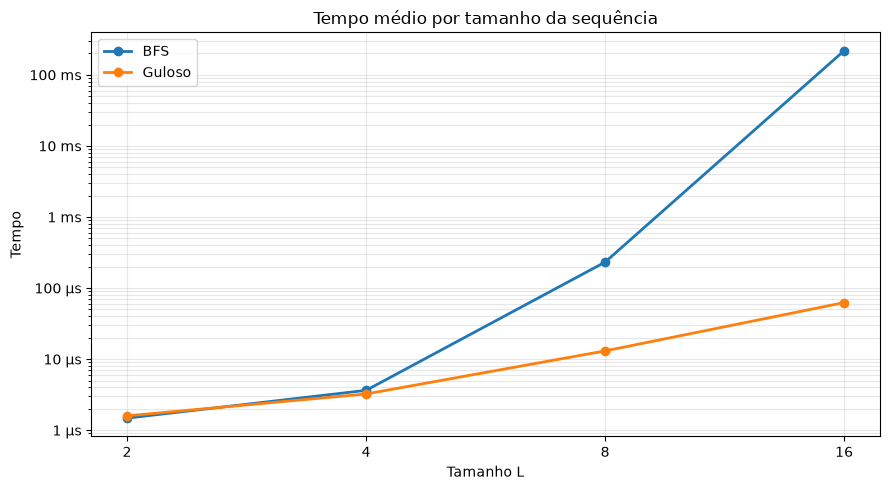

In [ ]:
media_tamanhos = []
media_tempo_bfs = []
media_tempo_guloso = []

for resultados_tamanho in resultados:
    media_tamanhos.append(resultados_tamanho[0][0])
    media_tempo_bfs.append(sum(r[1] for r in resultados_tamanho) / len(resultados_tamanho))
    media_tempo_guloso.append(sum(r[4] for r in resultados_tamanho) / len(resultados_tamanho))

fig, eixo = plt.subplots(figsize=(9, 5))

eixo.plot(media_tamanhos, media_tempo_bfs, marker="o", linewidth=2, label="BFS")
eixo.plot(media_tamanhos, media_tempo_guloso, marker="o", linewidth=2, label="Guloso")
eixo.set_xscale("log", base=2)
eixo.set_yscale("log")
eixo.xaxis.set_major_formatter(EngFormatter())
eixo.yaxis.set_major_formatter(EngFormatter(unit="s"))
eixo.set_title("Tempo médio por tamanho da sequência")
eixo.set_xlabel("Tamanho L")
eixo.set_ylabel("Tempo")
eixo.grid(True, which="both", alpha=0.3)
eixo.legend()

fig.tight_layout()
plt.show()

# III. Otimização com gradiente descendente

## III.B. Função de erro

A função de erro compara, posição a posição, o valor atual com o valor esperado, se forem iguais, não há erro e quanto mais diferentes forem, maior será o erro. O somatório faz com que os erros sejam acumulados para todas as posições da sequência e quanto maiores forem os erros individuais, maior será o erro total. Cada erro individual é elevado ao quadrado, para que não existam termos negativos que diminuam o erro acumulado. Busca-se, então, minimizar o erro acumulado, que indica um menor erro posição a posição, por meio de transformações em x até que o erro se aproxime de 0.

## III.C. Gradiente descendente sem custo

In [ ]:
def funcao_erro(x_previsto, y_real):
    erro_acumulado = 0

    for pos in range(len(x_previsto)):
        erro = (x_previsto[pos] - y_real[pos]) ** 2
        erro_acumulado += erro

    return erro_acumulado


def derivada_funcao_erro(x_previsto, y_real):
    derivada = np.zeros(len(x_previsto))

    for pos in range(len(x_previsto)):
        derivada[pos] = 2 * (x_previsto[pos] - y_real[pos])

    return derivada


def gradiente_descendente(inicio, resultado, lr=0.1, iteracoes=10):

    x = np.array(inicio, dtype=float, copy=True)
    y = np.array(resultado, dtype=float, copy=True)

    historico = [x.copy()]
    transformacoes = []

    for _ in range(iteracoes):
        gradiente = derivada_funcao_erro(x, y)
        novo_x = x - lr * gradiente

        transformacoes.append(novo_x - x)
        x = novo_x
        historico.append(x.copy())

    return historico, transformacoes


x = np.array([0, 0, 1], dtype=float)
y = np.array([0, 1, 1], dtype=float)

historico, transformacoes = gradiente_descendente(x, y, lr=0.2, iteracoes=10)

# Mostra a transformação junto aos estados que ela conecta.
for i, transformacao in enumerate(transformacoes):
    estado_atual = historico[i]

    print(f"Passo {i + 1}")
    print(f"  Estado atual:  {estado_atual.tolist()}")
    print(f"  Erro: {funcao_erro(estado_atual, y):.6f}")
    print(f"  Transformação: {transformacao.tolist()}")
    print()

print()
print("Estado final:", historico[-1].tolist())
print("Erro final:", funcao_erro(historico[-1], y))

# Taxa maior que 1/2 pode ultrapassar o alvo e produzir um estado negativo.
# Na primeira posição, x=1 e y=0, então o gradiente é 2.
# Com taxa 0.6, o novo valor é 1 - 0.6 * 2 = -0.2.
x_negativo = np.array([1, 0, 1], dtype=float)
y_negativo = np.array([0, 1, 1], dtype=float)
lr_alta = 0.6

print()
print(f"Exemplo com taxa de aprendizado {lr_alta}:")
historico_negativo, transformacoes_negativas = gradiente_descendente(
    x_negativo, y_negativo, lr=lr_alta, iteracoes=3
)

for i, transformacao in enumerate(transformacoes_negativas):
    estado_atual = historico_negativo[i]

    print(f"Passo {i + 1}")
    print(f"  Estado atual:  {estado_atual.tolist()}")
    print(f"  Erro: {funcao_erro(estado_atual, y_negativo):.6f}")
    print(f"  Transformação: {transformacao.tolist()}")
    print()

print()
print("Estado final:", historico_negativo[-1].tolist())
print("Erro final:", funcao_erro(historico_negativo[-1], y_negativo))

Passo 1
  Estado atual:  [0.0, 0.0, 1.0]
  Erro: 1.000000
  Transformação: [0.0, 0.4, 0.0]

Passo 2
  Estado atual:  [0.0, 0.4, 1.0]
  Erro: 0.360000
  Transformação: [0.0, 0.24, 0.0]

Passo 3
  Estado atual:  [0.0, 0.64, 1.0]
  Erro: 0.129600
  Transformação: [0.0, 0.14400000000000002, 0.0]

Passo 4
  Estado atual:  [0.0, 0.784, 1.0]
  Erro: 0.046656
  Transformação: [0.0, 0.08640000000000003, 0.0]

Passo 5
  Estado atual:  [0.0, 0.8704000000000001, 1.0]
  Erro: 0.016796
  Transformação: [0.0, 0.05184, 0.0]

Passo 6
  Estado atual:  [0.0, 0.9222400000000001, 1.0]
  Erro: 0.006047
  Transformação: [0.0, 0.03110400000000002, 0.0]

Passo 7
  Estado atual:  [0.0, 0.9533440000000001, 1.0]
  Erro: 0.002177
  Transformação: [0.0, 0.018662399999999968, 0.0]

Passo 8
  Estado atual:  [0.0, 0.9720064, 1.0]
  Erro: 0.000784
  Transformação: [0.0, 0.011197440000000003, 0.0]

Passo 9
  Estado atual:  [0.0, 0.98320384, 1.0]
  Erro: 0.000282
  Transformação: [0.0, 0.0067184639999999796, 0.0]

Passo 

## III.D. Gradiente descendente com custo

In [ ]:
def funcao_erro(x_previsto, y_real):
    erro_acumulado = 0

    for pos in range(len(x_previsto)):
        erro_acumulado += (x_previsto[pos] - y_real[pos]) ** 2

    return erro_acumulado


def derivada_funcao_erro(x_previsto, y_real):
    derivada = np.zeros(len(x_previsto))

    for pos in range(len(x_previsto)):
        derivada[pos] = 2 * (x_previsto[pos] - y_real[pos])

    return derivada


def gerar_z(gradiente):
    return (gradiente / 2) ** 2


def derivada_gerar_z(gradiente):
    return 2 * (gradiente / 2) * (1 / 2)


def custo(z):
    custo_total = 0.0
    peso_anterior = 0.0

    for peso_atual in z:
        diferenca = peso_atual - peso_anterior
        custo_total += diferenca ** 2
        peso_anterior = peso_atual

    # Depois da última posição, o peso volta a zero.
    custo_total += peso_anterior ** 2

    return custo_total / 2


def derivada_custo(z):
    derivada = np.zeros(len(z))

    for i in range(len(z)):
        peso_atual = z[i]

        if i == 0:
            peso_anterior = 0.0
            
        else:
            peso_anterior = z[i - 1]

        if i == len(z) - 1:
            peso_seguinte = 0.0

        else:
            peso_seguinte = z[i + 1]

        diferenca_com_anterior = peso_atual - peso_anterior
        diferenca_com_seguinte = peso_atual - peso_seguinte
        derivada[i] = diferenca_com_anterior + diferenca_com_seguinte

    return derivada


def erro_com_custo(erro, custo_atual, peso):
    return erro + peso * custo_atual


def funcao_objetivo(x, y, peso=1):
    erro = funcao_erro(x, y)
    gradiente_erro = derivada_funcao_erro(x, y)
    z = gerar_z(gradiente_erro)

    return erro_com_custo(erro, custo(z), peso)


def derivada_objetivo(x, y, peso=1):
    gradiente_erro = derivada_funcao_erro(x, y)
    z = gerar_z(gradiente_erro)

    derivada_z = derivada_gerar_z(gradiente_erro)
    derivada_gradiente_em_x = 2
    gradiente_custo = derivada_custo(z) * derivada_z * derivada_gradiente_em_x

    return gradiente_erro + peso * gradiente_custo


def gradiente_descendente_com_custo(inicio, resultado, lr=0.1, iteracoes=10, peso=1):
    x = np.array(inicio, dtype=float, copy=True)
    y = np.array(resultado, dtype=float, copy=True)

    historico = [x.copy()]
    transformacoes = []

    for _ in range(iteracoes):
        gradiente = derivada_objetivo(x, y, peso)
        novo_x = x - lr * gradiente

        transformacoes.append(novo_x - x)
        x = novo_x
        historico.append(x.copy())

    return historico, transformacoes


z_separadas = np.array([1, 0, 1, 0, 1], dtype=float)
z_consecutivas = np.array([1, 1, 1, 0, 0], dtype=float)

print("Custo de mudanças separadas:", custo(z_separadas))
print("Custo de mudanças consecutivas:", custo(z_consecutivas))
print()

inicio = np.array([0, 1, 0, 1, 0, 1, 0], dtype=float)
resultado = np.zeros(len(inicio))

for peso_teste in [0, 0.1, 1, 3]:
    historico, transformacoes = gradiente_descendente_com_custo(
        inicio, resultado, lr=0.05, iteracoes=30, peso=peso_teste
    )

    estado_final = historico[-1]
    z_final = gerar_z(derivada_funcao_erro(estado_final, resultado))

    estado_verificado = inicio.copy()
    for transformacao in transformacoes:
        estado_verificado += transformacao

    assert np.allclose(estado_verificado, estado_final)

    print("Peso:", peso_teste)
    print("Erro final:", funcao_erro(estado_final, resultado))
    print("Custo final:", custo(z_final))
    print("Objetivo final:", funcao_objetivo(estado_final, resultado, peso_teste))
    print()

Custo de mudanças separadas: 3.0
Custo de mudanças consecutivas: 1.0

Peso: 0
Erro final: 0.005391030899743292
Custo final: 9.687738053995654e-06
Objetivo final: 0.005391030899743292

Peso: 0.1
Erro final: 0.004355865971705991
Custo final: 6.324522787822059e-06
Objetivo final: 0.004356498423984774

Peso: 1
Erro final: 0.001459816431089442
Custo final: 7.103546708262384e-07
Objetivo final: 0.0014605267857602682

Peso: 3
Erro final: 0.000361075145106565
Custo final: 4.345842013790898e-08
Objetivo final: 0.0003612055203669787



Foi usado $z_i=g_i^2/4$, em que $g_i$ é o gradiente do erro. Como $g_i=2(x_i-y_i)$, então $z_i=(x_i-y_i)^2$. Assim, $z_i$ representa o erro de cada posição e não depende da direção da mudança.

O custo é

$$C(z)=\frac{1}{2}\sum_{i=0}^{n}(z_i-z_{i-1})^2, \qquad z_{-1}=z_n=0.$$

Quando dois pesos vizinhos são iguais, a diferença é zero e quando são diferentes, o custo aumenta. Com zeros e uns, cada grupo tem uma entrada e uma saída, por isso, o resultado é dividido por dois, para não contar duas vezes. Essa função penalizar mais mudanças separadas em relação a mudanças em grupos/consecutivas.

Cada $z_i$ aparece na diferença com a posição anterior e com a seguinte. Então,

$$\frac{\partial C}{\partial z_i}=(z_i-z_{i-1})+(z_i-z_{i+1}).$$

Como $z_i=(g_i/2)^2$, então $\partial z_i/\partial g_i=2(g_i/2)(1/2)=g_i/2$. Como $g_i=2(x_i-y_i)$, obtém-se $\partial g_i/\partial x_i=2$. Assim, pela regra da cadeia, $\partial z_i/\partial x_i=g_i$. Portanto,

$$\frac{\partial J}{\partial x_i}=g_i+\lambda[(z_i-z_{i-1})+(z_i-z_{i+1})]g_i.$$

Foram testados os pesos 0, 0.1, 1 e 3. Neste teste, o erro final diminuiu quando o peso aumentou.